## Baseline: Logistic Regression with TF-IDF features

In [18]:
# imports
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import f1_score
import matplotlib.pyplot as plt

### Loading and processing data

In [19]:
# loading processed data

train = pd.read_json("../data/train_processed.jsonl", lines=True)
valid = pd.read_json("../data/dev_processed.jsonl", lines=True)
test = pd.read_json("../data/test_processed.jsonl", lines=True)

In [20]:
# formatting training data

# concatenating preceding turns and question
train["input_text"] = (
    train["preceding_turns"] + "\n\n" + train["question"]
)

# verifying
#print(train["input_text"].iloc[14])

# fitting and vectorizing (TF-IDF)
vectorizer = TfidfVectorizer()

X_train, y_train = train["input_text"], train["label"]
X_train_tfidf = vectorizer.fit_transform(X_train)

# checking shape
print(X_train_tfidf.shape)

# checking features
feature_names = vectorizer.get_feature_names_out()
print("Feature names:", feature_names)

(345, 10085)
Feature names: ['000' '001' '01' ... 'флага' 'флаги' 'человек']


In [21]:
# formatting validation data

# concatenating preceding turns (real context) and question
valid["input_real"] = (
    valid["preceding_turns"] + "\n\n" + valid["question"]
)

# concatenating preceding turns (swapped context) and question
valid["input_swapped"] = (
    valid["swapped_context"] + "\n\n" + valid["question"]
)

# concatenating preceding turns (no context) and question
valid["input_empty"] = (
    "" + "\n\n" + valid["question"]
)

# verifying
#print(valid["input_real"].iloc[14])
#print(valid["input_swapped"].iloc[14])
#print(valid["input_empty"].iloc[14])

# vectorizing
y_valid = valid["label"]

X_valid_real = valid["input_real"]
X_valid_real_tfidf = vectorizer.transform(X_valid_real)

X_valid_swapped = valid["input_swapped"]
X_valid_swapped_tfidf = vectorizer.transform(X_valid_swapped)

X_valid_empty = valid["input_empty"]
X_valid_empty_tfidf = vectorizer.transform(X_valid_empty)

# checking shapes
print(X_valid_real_tfidf.shape)
print(X_valid_swapped_tfidf.shape)
print(X_valid_empty_tfidf.shape)

(90, 10085)
(90, 10085)
(90, 10085)


In [22]:
# formatting test data

### Training the model with default parameters and evaluating on the validation data

In [23]:
# training the model

model = LogisticRegression()
model.fit(X_train_tfidf, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [24]:
# predicting

# real context
y_pred_valid_real = model.predict(X_valid_real_tfidf)

# checking accurarcy and macro F1
accuracy_real = accuracy_score(y_valid, y_pred_valid_real)
print(f"Accuracy real context: {accuracy_real:.2f}")
print("Macro F1 real context:", f1_score(y_valid, y_pred_valid_real, average="macro"))

# swapped context
y_pred_valid_swapped = model.predict(X_valid_swapped_tfidf)

accuracy_swapped = accuracy_score(y_valid, y_pred_valid_swapped)
print(f"Accuracy swapped context: {accuracy_swapped:.2f}")
print("Macro F1 swapped context:", f1_score(y_valid, y_pred_valid_swapped, average="macro"))

# empty context
y_pred_valid_empty = model.predict(X_valid_empty_tfidf)

accuracy_empty = accuracy_score(y_valid, y_pred_valid_empty)
print(f"Accuracy no context: {accuracy_empty:.2f}")
print("Macro F1 empty context:", f1_score(y_valid, y_pred_valid_real, average="macro"))

Accuracy real context: 0.63
Macro F1 real context: 0.3877551020408163
Accuracy swapped context: 0.62
Macro F1 swapped context: 0.3835616438356164
Accuracy no context: 0.60
Macro F1 empty context: 0.3877551020408163


Confusion Matrix real context:
[[0 32]
 [1 57]]


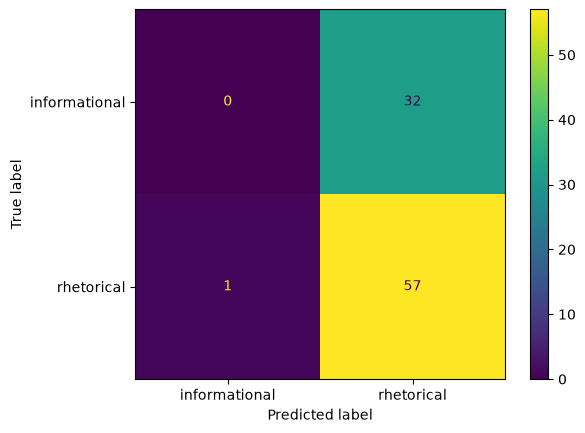

Confusion Matrix swapped context:
[[0 32]
 [2 56]]


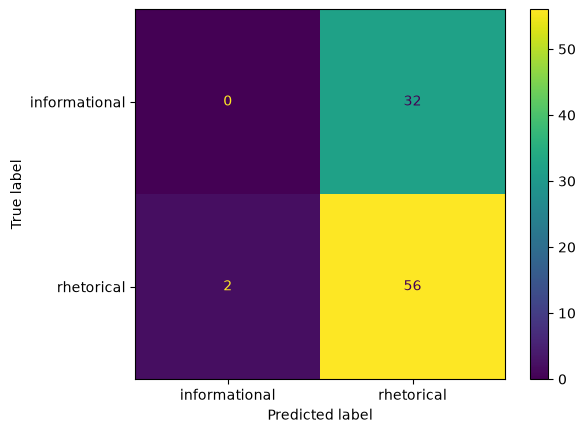

Confusion Matrix empty context:
[[13 19]
 [17 41]]


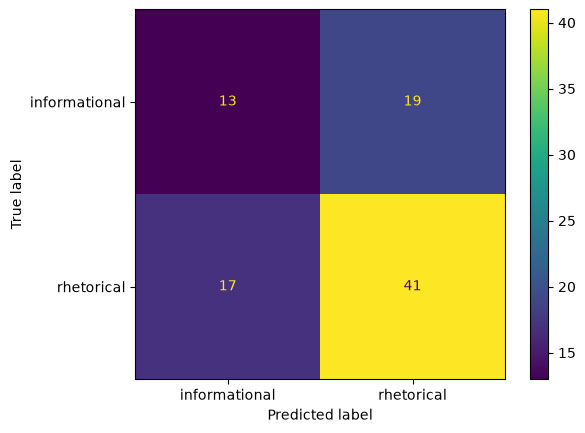

In [25]:
cm_real = confusion_matrix(y_valid, y_pred_valid_real)
print("Confusion Matrix real context:")
print(f"[[{cm_real[0,0]} {cm_real[0,1]}]")
print(f" [{cm_real[1,0]} {cm_real[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_real, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

cm_swapped= confusion_matrix(y_valid, y_pred_valid_swapped)
print("Confusion Matrix swapped context:")
print(f"[[{cm_swapped[0,0]} {cm_swapped[0,1]}]")
print(f" [{cm_swapped[1,0]} {cm_swapped[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_swapped, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

cm_empty = confusion_matrix(y_valid, y_pred_valid_empty)
print("Confusion Matrix empty context:")
print(f"[[{cm_empty[0,0]} {cm_empty[0,1]}]")
print(f" [{cm_empty[1,0]} {cm_empty[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_empty, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

Simple baseline with default model parameters:  

Accuracy real context: 0.63  
Macro F1 real context: 0.3878  

Accuracy swapped context: 0.62  
Macro F1 swapped context: 0.3836  

Accuracy no context: 0.60  
Macro F1 empty context: 0.3878  

on validation set.

Confusion Matrix real context:  
[[0 32]  
 [1 57]]  

Confusion Matrix empty context:  
[[13 19]  
 [17 41]]  

Confusion Matrix swapped context:  
[[0 32]  
 [2 56]]  
 

Model seems to be biased towards predicting rhetorical questions. With the real context, it only predicted one question as informational (and that question happened to be rhetorical). It was the same case for the swapped context - except that two rhetorical questions were falsely predicted as informational. In both cases, the model acts like a majority classifier.  
Interestingly, with no context, 13 informational questions were predicted correctly, and the predictions were more balanced in general.  

Results so far suggest that the model is unable to distinguish the pragmatic role of the context.

Possible reasons (hypotheses):  
- class imbalance (in favor of RQs)
- context length (longer contexts might drown out question features)
- small training set (features may be sparse)
- too strong default regularization

### Hyperparameter tuning

In [26]:
# training adjusted model with balanced class weight

model_balanced = LogisticRegression(class_weight="balanced")
model_balanced.fit(X_train_tfidf, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

In [27]:
# testing balanced model on real context validation set

# real context
y_pred_valid_real = model_balanced.predict(X_valid_real_tfidf)

# checking accurarcy and macro F1
accuracy_real = accuracy_score(y_valid, y_pred_valid_real)
print(f"Accuracy real context: {accuracy_real:.2f}")
print("Macro F1 real context:", f1_score(y_valid, y_pred_valid_real, average="macro"))


Accuracy real context: 0.69
Macro F1 real context: 0.6213942307692308


Confusion Matrix real context:
[[12 20]
 [8 50]]


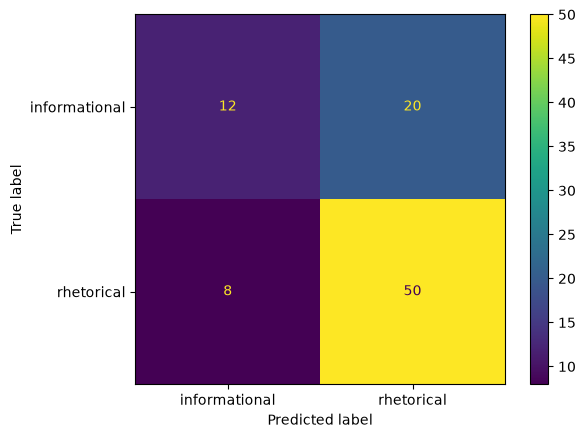

In [28]:
cm_real = confusion_matrix(y_valid, y_pred_valid_real)
print("Confusion Matrix real context:")
print(f"[[{cm_real[0,0]} {cm_real[0,1]}]")
print(f" [{cm_real[1,0]} {cm_real[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_real, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

significant improvement with balanced class weight  
-> sensible to keep exploring improvements

In [29]:
# parameter grid with different regularization and class weight

param_grid = {
    "C": [0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

# looping over grid to find the best model
models = []

for params in ParameterGrid(param_grid):

    # training new model
    model_new = LogisticRegression(**params)
    model_new.fit(X_train_tfidf, y_train)

    # predicting for real context validation set
    y_pred_valid_real = model_new.predict(X_valid_real_tfidf)

    # checking accurarcy and macro F1
    accuracy_real = accuracy_score(y_valid, y_pred_valid_real)
    f1_real = f1_score(y_valid, y_pred_valid_real, average="macro")

    models.append({
        **params,
        "accuracy": accuracy_real,
        "macro_f1": f1_real
    })

models_df = pd.DataFrame(models)
models_df.sort_values("macro_f1", ascending=False)

,C,class_weight,accuracy,macro_f1
3,1.0,balanced,0.688889,0.621394
5,10.0,balanced,0.644444,0.576720
1,0.1,balanced,0.611111,0.566056
4,10.0,NaN,0.666667,0.548797
0,0.1,NaN,0.644444,0.391892
2,1.0,NaN,0.633333,0.387755


best model: balanced class weight and C = 1.0  

balanced class weight generally improved the models' performances

### Training and evaluating best model on the validation set

In [30]:
final_model = LogisticRegression(
    C=1.0,
    class_weight="balanced"
)

final_model.fit(X_train_tfidf, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the fol

In [31]:
# predicting

# real context
y_pred_valid_real = final_model.predict(X_valid_real_tfidf)

# checking accurarcy and macro F1
accuracy_real = accuracy_score(y_valid, y_pred_valid_real)
print(f"Accuracy real context: {accuracy_real:.2f}")
f1_real = f1_score(y_valid, y_pred_valid_real, average="macro")
print("Macro F1 real context:", f1_real)

# swapped context
y_pred_valid_swapped = final_model.predict(X_valid_swapped_tfidf)

accuracy_swapped = accuracy_score(y_valid, y_pred_valid_swapped)
print(f"Accuracy swapped context: {accuracy_swapped:.2f}")
f1_swapped = f1_score(y_valid, y_pred_valid_swapped, average="macro")
print("Macro F1 swapped context:", f1_swapped)

# empty context
y_pred_valid_empty = final_model.predict(X_valid_empty_tfidf)

accuracy_empty = accuracy_score(y_valid, y_pred_valid_empty)
print(f"Accuracy no context: {accuracy_empty:.2f}")
f1_empty = f1_score(y_valid, y_pred_valid_empty, average="macro")
print("Macro F1 empty context:", f1_empty)

Accuracy real context: 0.69
Macro F1 real context: 0.6213942307692308
Accuracy swapped context: 0.50
Macro F1 swapped context: 0.4109090909090909
Accuracy no context: 0.52
Macro F1 empty context: 0.5173961840628507


Confusion Matrix real context:
[[12 20]
 [8 50]]


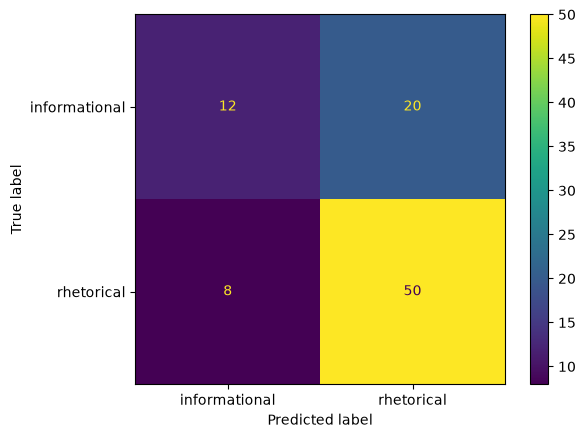

Confusion Matrix swapped context:
[[5 27]
 [18 40]]


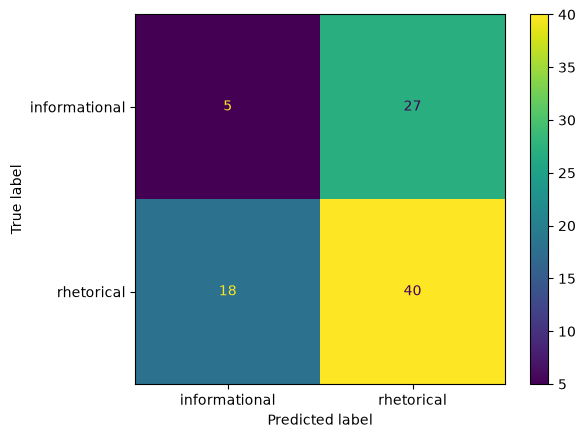

Confusion Matrix empty context:
[[28 4]
 [39 19]]


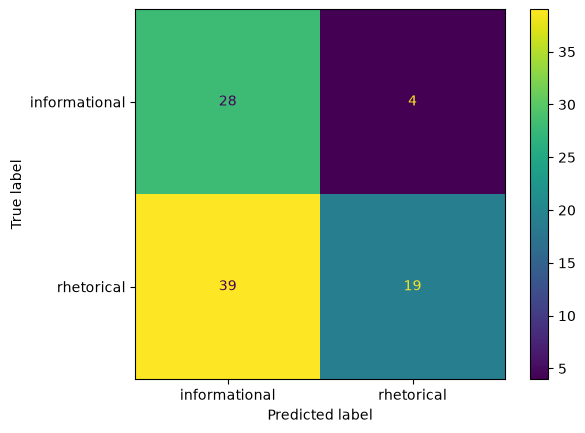

In [32]:
cm_real = confusion_matrix(y_valid, y_pred_valid_real)
print("Confusion Matrix real context:")
print(f"[[{cm_real[0,0]} {cm_real[0,1]}]")
print(f" [{cm_real[1,0]} {cm_real[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_real, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

cm_swapped= confusion_matrix(y_valid, y_pred_valid_swapped)
print("Confusion Matrix swapped context:")
print(f"[[{cm_swapped[0,0]} {cm_swapped[0,1]}]")
print(f" [{cm_swapped[1,0]} {cm_swapped[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_swapped, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

cm_empty = confusion_matrix(y_valid, y_pred_valid_empty)
print("Confusion Matrix empty context:")
print(f"[[{cm_empty[0,0]} {cm_empty[0,1]}]")
print(f" [{cm_empty[1,0]} {cm_empty[1,1]}]]")

disp = ConfusionMatrixDisplay(confusion_matrix=cm_empty, display_labels=["informational", "rhetorical"])
disp.plot()
plt.show()

Accuracy real context: 0.69  
Macro F1 real context: 0.6214  

Accuracy swapped context: 0.50  
Macro F1 swapped context: 0.4109  

Accuracy no context: 0.52  
Macro F1 empty context: 0.5174  

- real context performs best
- swapped context performs worst  
based on macro F1

- real context and swapped context: better recall for RQs (but swapped worse on both classes)
- no context: better recall for IQs (-> does context influence model's predictions?)

=> results on validation set so far suggest that info in original context contributes to classification  
However, model might not understand the contextual relevance
- logistic regression with TF-IDF captures lexical patterns, not complex linguistic relationships
- the new swapped contexts might change interpretation of the question  
-> how predictions respond to context manipulation


### Evaluating the final model on the test set

Mostly from here:  
https://medium.com/@jumjumjum/python-logistic-regression-with-nlp-101cc10e1be7

Possibly useful:  
https://www.geeksforgeeks.org/machine-learning/text-classification-using-logistic-regression/

https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_text_feature_extraction.html?utm_source=chatgpt.com